In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
import csv
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625





Loading cached filtered B ...
density 'Dn1': mean = 1.0000, spread std/mean = 0.0590
domain average beta = 2<P>/<B^2> = 0.9618  (nominal beta_p = 1)
(if this is off by a constant factor, that factor is the pressure normalisation)
domain rho_i        = 0.9807 d_i0   (expect ~sqrt(beta) = 0.9807)
found 244 current sheets
measured 244 sheets that had a usable rectangle


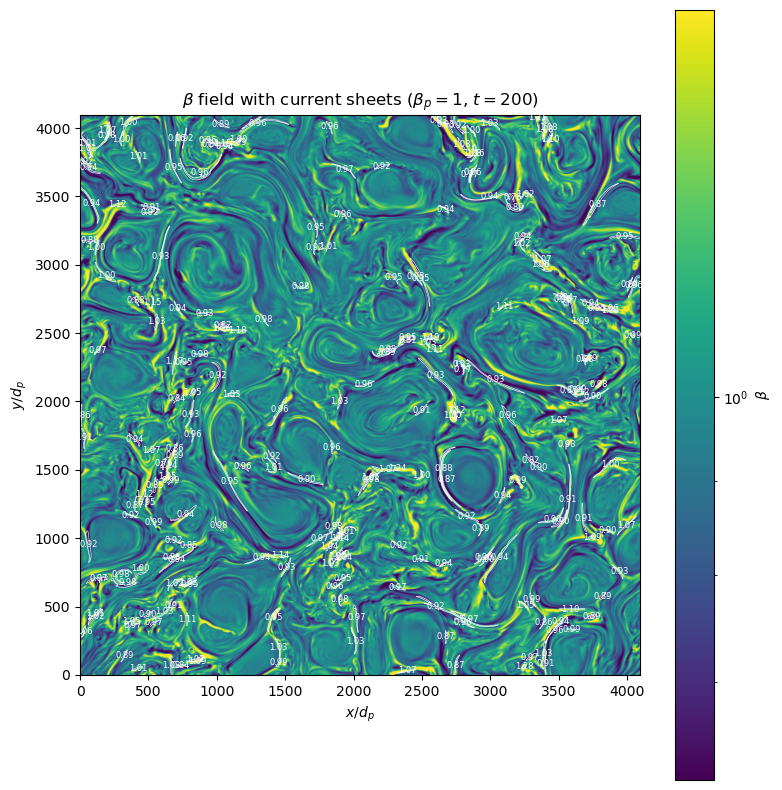

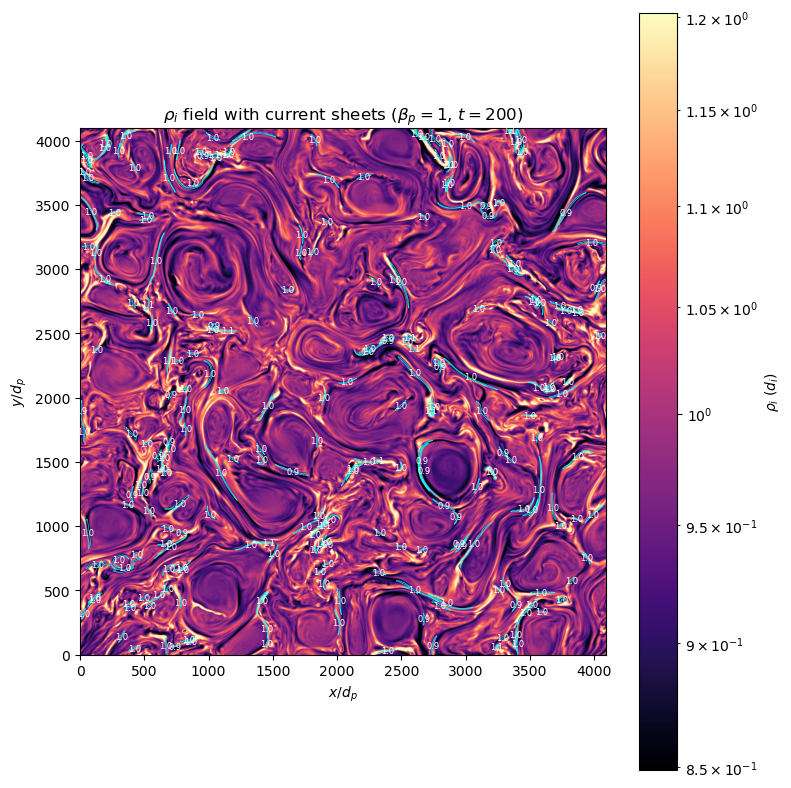

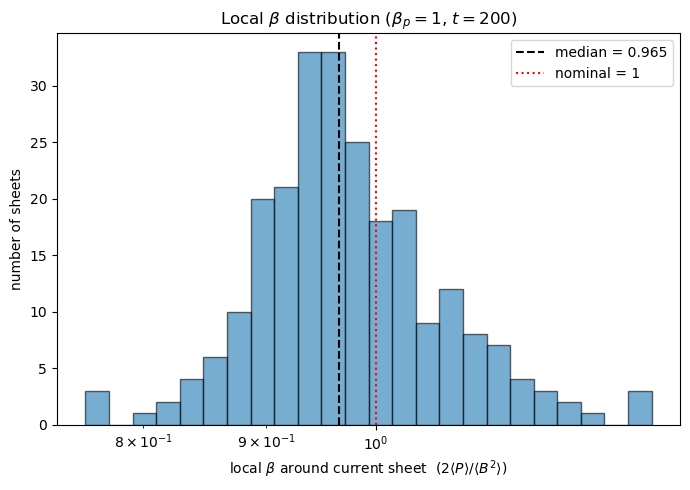

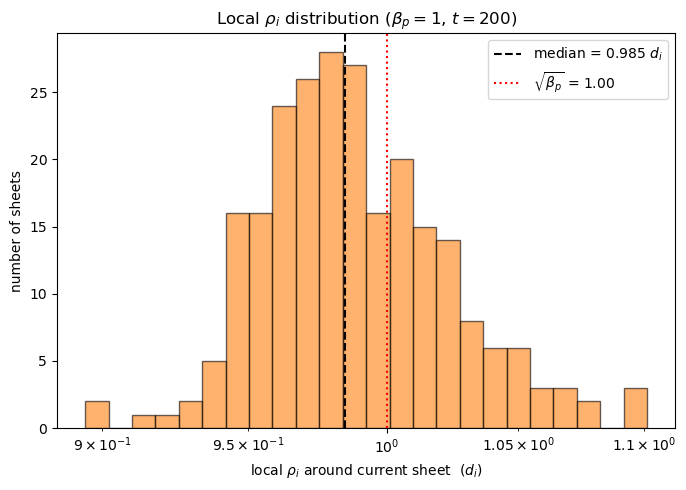


--- thickness statistics in beta bins ---
          beta range     N   median thick (d_i)   mean thick (d_i)
  0.757-  0.867    16                0.755              0.729
  0.867-  0.993   142                0.673              0.730
  0.993-  1.137    73                0.729              0.756
  1.137-  1.302    12                0.701              0.744


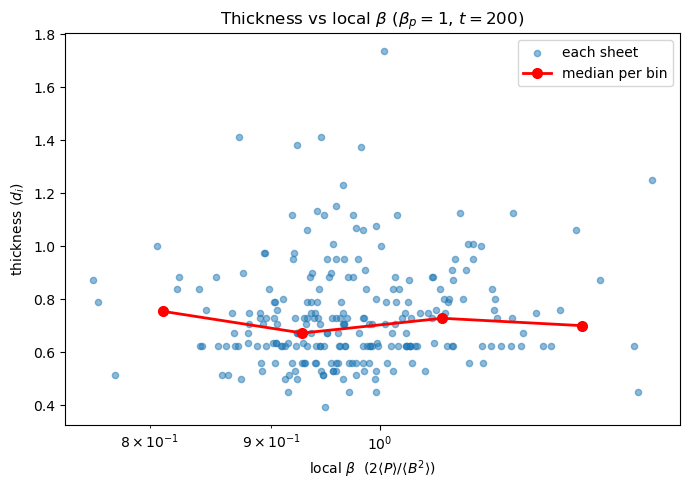

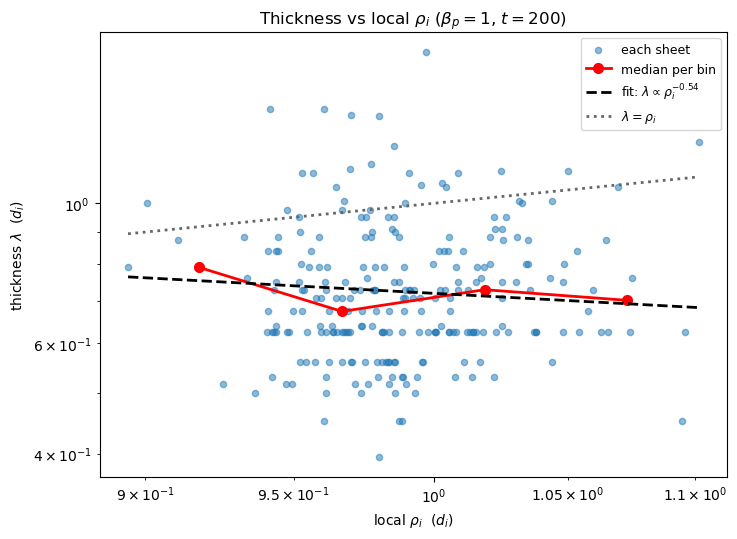

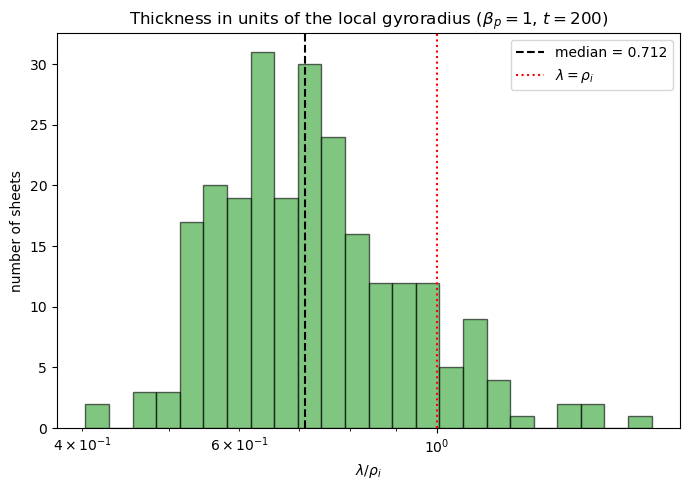


--- overall statistics ---
local beta     : median = 0.965, mean = 0.978
local rho_i    : median = 0.985 d_i (sqrt(beta_p) = 1.000)
thickness      : median = 0.707, mean = 0.741 d_i
lambda / rho_i : median = 0.712  (16-84%: 0.571 to 0.928)
power-law fit   : lambda = 0.719 rho_i^-0.540

NOTE: rho_i = sqrt(beta/n), full scalar pressure, v_th = sqrt(2T/m_i), |B| total.

Everything saved in:  cs_beta_analysis_beta1_t200/


In [3]:
# ============================================================
#  Current sheets:  local beta + local ion gyroradius  +  thickness
#  ------------------------------------------------------------
#  For ONE simulation snapshot this script:
#    1. builds the plasma-beta field (from FILTERED B; cached)
#    2. detects the current sheets (your method)
#    3. for each sheet: measures thickness, the local beta, and the local ION
#       GYRORADIUS in a rectangle around it. Local averages use the SAME
#       convention as before: ratio of averages, 2<P>/<B^2>.
#    4. saves histograms of local beta and local rho_i
#    5. saves a picture of every sheet
#    6. saves the table + scatter of beta vs thickness
#    7. NEW: thickness vs local rho_i -- scatter, binned medians, power-law fit,
#            and the distribution of lambda/rho_i
#
#  ---- how the local gyroradius is obtained -------------------------------
#  In code units (m_i = e = B_0 = n_0 = 1, so v_A0 = d_i0 = Omega_i0 = 1):
#
#      rho_i = v_th / Omega_i ,   v_th = sqrt(2 T / m_i) ,
#      Omega_i = |B| ,            T    = P / n
#
#  which reduces exactly to
#
#      rho_i / d_i0        = sqrt( beta / n )        <-- fixed code units
#      rho_i / d_i(local)  = sqrt( beta )            <-- local d_i units
#
#  because d_i(local)/d_i0 = 1/sqrt(n). Checked: with n = 1 this gives
#  rho_i/d_i = 0.25, 0.5, 1, 2, 4 for beta = 1/16, 1/4, 1, 4, 16.
#
#  TWO CONVENTIONS TO STATE IN THE PAPER:
#  * the FULL (scalar) pressure P = (P_par + 2 P_perp)/3 is used, i.e. the
#    isotropic-equivalent gyroradius. Identical to the strict perpendicular
#    definition when T_par = T_perp.
#  * v_th = sqrt(2 T/m) is a convention, and it is what makes rho_i = sqrt(beta) d_i.
#    Some authors use sqrt(T/m) instead, which makes every rho_i smaller by sqrt(2).
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi

# -----------------------------
# SETTINGS  (change these)
# -----------------------------
beta     = 1                 # which run: 0.0625, 0.25, 1, 4, 16
time     = 200               # which snapshot
sim_tag  = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_analysis_beta{beta}_t{time}")   # all results go here

px_per_di = 16.0             # pixels per ion inertial length (turns thickness into d_i)
box_pad   = 5                # padding (px) added around the sheet to make the rectangle
SAVE_SHEET_PICTURES = False   # set False if you don't want one image per sheet

P_PAR_TAG = "Ppar1"          # proton parallel pressure
P_PER_TAG = "Pper1"          # proton perpendicular pressure
N_TAG     = "Dn1"              # DENSITY -- needed for rho_i in fixed d_i0 units.
                             # If this tag is wrong the script falls back to n = 1
                             # (see STEP 1); check with os.listdir(base_path).

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/sheets", exist_ok=True)

# filter parameters for this beta (same table as your detection)
if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

dx = dy = 0.0625


# small helper: open one HDF5 field file and return the array (transposed, as you do)
def load(tag):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


# ============================================================
# STEP 0.  Filtered B  (cached; reused across your scripts)
#          raw fields are only read on a cache miss
# ============================================================
cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_file):
    print("Loading cached filtered B ...")
    d = np.load(cache_file)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)


# ============================================================
# STEP 1.  Plasma beta field  +  ion gyroradius field
#   - pointwise fields are used only for the MAPS
#   - region "average beta"  = 2<P>/<B^2>          (ratio of averages, as before)
#   - region rho_i          = sqrt(beta / <n>)
# ============================================================
B2    = Bx_f**2 + By_f**2 + Bz_f**2                 # |B|^2  (filtered)
P_mag = 0.5 * B2                                    # magnetic pressure

# scalar pressure from the gyrotropic tensor:  trace = P_par + 2 P_perp
P_par  = load(P_PAR_TAG)
P_perp = load(P_PER_TAG)
P_scalar = (P_par + 2.0 * P_perp) / 3.0

beta_field = P_scalar / P_mag                     # pointwise beta (for the colour map only)

# density: needed to put rho_i in FIXED d_i0 units, because d_i(local) ~ n^(-1/2)
try:
    n_field = load(N_TAG)
    print(f"density '{N_TAG}': mean = {n_field.mean():.4f}, "
          f"spread std/mean = {n_field.std()/n_field.mean():.4f}")
except (OSError, KeyError, FileNotFoundError):
    n_field = np.ones_like(B2)
    print(f"WARNING: could not read density tag '{N_TAG}'. Falling back to n = 1, i.e.\n"
          f"         rho_i is now in units of the LOCAL d_i rather than d_i0.\n"
          f"         Check the real tag with:  os.listdir('{base_path}')")

# pointwise gyroradius field, in d_i0 (only used for the map)
rho_i_field = np.sqrt(beta_field / n_field)


def avg_beta(region_mask):
    """Region-averaged plasma beta = 2<P>/<B^2> (ratio of averages, not mean of ratios)."""
    return float(2.0 * P_scalar[region_mask].mean() / B2[region_mask].mean())


def avg_rho_i(region_mask):
    """Region ion gyroradius in d_i0 = sqrt(beta / <n>), from the local beta above.

    rho_i = v_th/Omega_i with v_th = sqrt(2T/m), Omega_i = |B|, T = P/n.
    |B| is the TOTAL field: the in-plane field reverses through zero inside a sheet,
    which would make rho_i diverge exactly where the sheets are.
    """
    return float(np.sqrt(avg_beta(region_mask) / n_field[region_mask].mean()))


# domain calibration: this is the definition that should match nominal beta_p
beta_domain = 2.0 * P_scalar.mean() / B2.mean()
print(f"domain average beta = 2<P>/<B^2> = {beta_domain:.4f}  (nominal beta_p = {beta})")
print("(if this is off by a constant factor, that factor is the pressure normalisation)")
print(f"domain rho_i        = {np.sqrt(beta_domain/n_field.mean()):.4f} d_i0"
      f"   (expect ~sqrt(beta) = {np.sqrt(beta_domain):.4f})")

# one colour scale (log) reused for all the beta pictures
beta_norm = LogNorm(vmin=np.percentile(beta_field, 1),
                    vmax=np.percentile(beta_field, 99))


# ============================================================
# STEP 2.  Detect the current sheets  (your method; B already filtered above)
# ============================================================
# out-of-plane current and |Jz|
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
J2 = np.abs(Jz)

# detection + cleaning (exactly your steps)
sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

# give each separate sheet its own number (1, 2, 3, ...)
labeled = measure.label(mask, connectivity=2)
n_sheets = labeled.max()
all_sheets_mask = labeled > 0          # every sheet, used to exclude cores from rectangles
print(f"found {n_sheets} current sheets")


# ============================================================
# STEP 3.  For each sheet: thickness + local beta + local rho_i around it
# ============================================================
sheet_id   = []     # sheet number
thickness  = []     # thickness in d_i0
local_beta = []     # 2<P>/<B^2> in the rectangle around the sheet
local_rho  = []     # ion gyroradius in d_i0

for k in range(1, n_sheets + 1):
    region = (labeled == k)                       # this sheet's pixels

    # --- thickness: largest circle that fits inside the sheet ---
    dist = ndi.distance_transform_edt(region)
    thick_di = (2 * dist.max()) / px_per_di

    # --- local quantities: a RECTANGLE around the sheet, with all sheet cores removed ---
    xs_r, ys_r = np.where(region)
    bx0 = max(0, xs_r.min() - box_pad)
    bx1 = min(beta_field.shape[0], xs_r.max() + box_pad + 1)
    by0 = max(0, ys_r.min() - box_pad)
    by1 = min(beta_field.shape[1], ys_r.max() + box_pad + 1)
    box_region = np.zeros_like(region)
    box_region[bx0:bx1, by0:by1] = True
    box_region = box_region & ~all_sheets_mask
    if box_region.sum() < 20:                     # almost no surrounding pixels -> skip
        continue
    beta_here = avg_beta(box_region)              # 2<P>/<B^2> over the surrounding plasma
    rho_here  = avg_rho_i(box_region)             # sqrt(beta / <n>)

    sheet_id.append(k)
    thickness.append(thick_di)
    local_beta.append(beta_here)
    local_rho.append(rho_here)

    # --- save a picture of this sheet with its local beta and rho_i ---
    if SAVE_SHEET_PICTURES:
        pad = box_pad + 10                        # show a little extra around the rectangle
        x0, x1 = max(0, xs_r.min() - pad), min(beta_field.shape[0], xs_r.max() + pad + 1)
        y0, y1 = max(0, ys_r.min() - pad), min(beta_field.shape[1], ys_r.max() + pad + 1)
        crop_beta   = beta_field[x0:x1, y0:y1]
        crop_region = region[x0:x1, y0:y1]
        crop_box    = box_region[x0:x1, y0:y1]
        ext = [x0, x1, y0, y1]

        plt.figure(figsize=(6, 5))
        plt.imshow(crop_beta.T, origin="lower", extent=ext, cmap="viridis", norm=beta_norm)
        plt.colorbar(label=r"$\beta$")
        plt.contour(crop_region.T, levels=[0.5], colors="white", linewidths=1.5, extent=ext)  # the sheet
        plt.contour(crop_box.T,    levels=[0.5], colors="cyan",  linewidths=0.8, extent=ext)  # the rectangle
        plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
        plt.title(f"sheet {k}:  $\\lambda$ = {thick_di:.2f} $d_i$,  "
                  + rf"$\beta$ = {beta_here:.3f},  $\rho_i$ = {rho_here:.2f} $d_i$")
        plt.tight_layout()
        plt.savefig(f"{out_dir}/sheets/sheet_{k:03d}.png", dpi=130)
        plt.close()

# turn the lists into arrays for convenience
sheet_id   = np.array(sheet_id)
thickness  = np.array(thickness)
local_beta = np.array(local_beta)
local_rho  = np.array(local_rho)
print(f"measured {len(sheet_id)} sheets that had a usable rectangle")

if len(local_beta) == 0:
    raise SystemExit("No sheets with a usable rectangle were found.")


# ============================================================
# STEP 4.  Overview pictures: beta map and rho_i map, with the sheets on top
# ============================================================
plt.figure(figsize=(8, 8))
plt.imshow(beta_field.T, origin="lower", cmap="viridis", norm=beta_norm)
plt.colorbar(label=r"$\beta$")
plt.contour(all_sheets_mask.T, levels=[0.5], colors="white", linewidths=0.4)
for i in range(len(sheet_id)):
    xr, yr = np.where(labeled == sheet_id[i])
    plt.text(xr.mean(), yr.mean(), f"{local_beta[i]:.2f}",
             color="white", fontsize=6, ha="center", va="center")
plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
plt.title(rf"$\beta$ field with current sheets ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(f"{out_dir}/overview_beta_with_sheets.png", dpi=300)
plt.show()

rho_norm = LogNorm(vmin=np.percentile(rho_i_field, 1), vmax=np.percentile(rho_i_field, 99))
plt.figure(figsize=(8, 8))
plt.imshow(rho_i_field.T, origin="lower", cmap="magma", norm=rho_norm)
plt.colorbar(label=r"$\rho_i\ (d_i)$")
plt.contour(all_sheets_mask.T, levels=[0.5], colors="cyan", linewidths=0.4)
for i in range(len(sheet_id)):
    xr, yr = np.where(labeled == sheet_id[i])
    plt.text(xr.mean(), yr.mean(), f"{local_rho[i]:.1f}",
             color="white", fontsize=6, ha="center", va="center")
plt.xlabel(r"$x/d_p$"); plt.ylabel(r"$y/d_p$")
plt.title(rf"$\rho_i$ field with current sheets ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(f"{out_dir}/overview_rho_i_with_sheets.png", dpi=300)
plt.show()


# ============================================================
# STEP 5.  Histograms of local beta and local rho_i
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta,
         bins=np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 25),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta), color="black", linestyle="--",
            label=f"median = {np.median(local_beta):.3f}")
plt.axvline(beta, color="red", linestyle=":", label=f"nominal = {beta}")
plt.xscale("log")
plt.xlabel(r"local $\beta$ around current sheet  ($2\langle P\rangle/\langle B^2\rangle$)")
plt.ylabel("number of sheets")
plt.title(rf"Local $\beta$ distribution ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(local_rho,
         bins=np.logspace(np.log10(local_rho.min()), np.log10(local_rho.max()), 25),
         alpha=0.6, edgecolor="black", color="tab:orange")
plt.axvline(np.median(local_rho), color="black", linestyle="--",
            label=f"median = {np.median(local_rho):.3f} $d_i$")
plt.axvline(np.sqrt(beta), color="red", linestyle=":",
            label=rf"$\sqrt{{\beta_p}}$ = {np.sqrt(beta):.2f}")
plt.xscale("log")
plt.xlabel(r"local $\rho_i$ around current sheet  $(d_i)$")
plt.ylabel("number of sheets")
plt.title(rf"Local $\rho_i$ distribution ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_rho_i.png", dpi=300)
plt.show()


# ============================================================
# STEP 6.  beta vs thickness:  per-sheet table, summary table, scatter plot
# ============================================================
# 6a. per-sheet table  (now also carries rho_i and lambda/rho_i)
with open(f"{out_dir}/beta_vs_thickness.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["sheet_id", "thickness_di", "local_beta", "local_rho_i_di",
                "thickness_over_rho_i"])
    for i in range(len(sheet_id)):
        w.writerow([int(sheet_id[i]), thickness[i], local_beta[i], local_rho[i],
                    thickness[i] / local_rho[i]])


def binned_medians(x, y, n_bins):
    """Median of y in log-spaced bins of x. Returns (centres, medians, counts, rows)."""
    edges = np.logspace(np.log10(x.min()), np.log10(x.max()), n_bins + 1)
    cen, med, cnt, rows = [], [], [], []
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        sel = (x >= lo) & (x < hi)
        if sel.sum() == 0:
            continue
        cen.append(np.sqrt(lo * hi))              # geometric centre (log axis)
        med.append(np.median(y[sel]))
        cnt.append(int(sel.sum()))
        rows.append([lo, hi, int(sel.sum()), np.median(y[sel]), np.mean(y[sel])])
    return np.array(cen), np.array(med), np.array(cnt), rows


# 6b. summary table: split sheets into beta bins and look at the thickness in each
bc_b, bm_b, cnt_b, summary_rows = binned_medians(local_beta, thickness, 4)
print("\n--- thickness statistics in beta bins ---")
print(f"{'beta range':>20} {'N':>5} {'median thick (d_i)':>20} {'mean thick (d_i)':>18}")
for r in summary_rows:
    print(f"{r[0]:7.3f}-{r[1]:7.3f} {r[2]:>5} {r[3]:>20.3f} {r[4]:>18.3f}")

with open(f"{out_dir}/beta_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_lo", "beta_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# 6c. scatter plot of thickness vs local beta, with the binned medians on top
plt.figure(figsize=(7, 5))
plt.scatter(local_beta, thickness, s=20, alpha=0.5, label="each sheet")
plt.plot(bc_b, bm_b, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$  ($2\langle P\rangle/\langle B^2\rangle$)")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()


# ============================================================
# STEP 7.  NEW: thickness vs local ION GYRORADIUS
#    (a) scatter + binned medians + power-law fit  lambda = a rho_i^b
#    (b) distribution of lambda/rho_i -- is the sheet at the gyroscale?
# ============================================================
bc_r, bm_r, cnt_r, rho_rows = binned_medians(local_rho, thickness, 4)

with open(f"{out_dir}/rho_i_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["rho_i_lo", "rho_i_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(rho_rows)

# power-law fit on the binned medians (bins with enough sheets)
ok = cnt_r >= 5
a_fit = b_fit = np.nan
if ok.sum() >= 2:
    b_fit, logA = np.polyfit(np.log10(bc_r[ok]), np.log10(bm_r[ok]), 1)
    a_fit = 10 ** logA

plt.figure(figsize=(7.5, 5.5))
plt.scatter(local_rho, thickness, s=20, alpha=0.5, label="each sheet")
plt.plot(bc_r, bm_r, "o-", color="red", lw=2, ms=7, label="median per bin")
if np.isfinite(b_fit):
    xx = np.logspace(np.log10(local_rho.min()), np.log10(local_rho.max()), 60)
    plt.plot(xx, a_fit * xx ** b_fit, "--", color="black", lw=2,
             label=rf"fit: $\lambda \propto \rho_i^{{{b_fit:.2f}}}$")
# reference line: sheets sitting exactly at the gyroscale
xx = np.logspace(np.log10(local_rho.min()), np.log10(local_rho.max()), 60)
plt.plot(xx, xx, ":", color="0.4", lw=2, label=r"$\lambda = \rho_i$")
plt.xscale("log"); plt.yscale("log")
plt.xlabel(r"local $\rho_i$  $(d_i)$")
plt.ylabel(r"thickness $\lambda$  $(d_i)$")
plt.title(rf"Thickness vs local $\rho_i$ ($\beta_p={beta}$, $t={time}$)")
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_rho_i.png", dpi=300)
plt.show()

ratio = thickness / local_rho
plt.figure(figsize=(7, 5))
plt.hist(ratio, bins=np.logspace(np.log10(ratio.min()), np.log10(ratio.max()), 25),
         alpha=0.6, edgecolor="black", color="tab:green")
plt.axvline(np.median(ratio), color="black", linestyle="--",
            label=f"median = {np.median(ratio):.3f}")
plt.axvline(1.0, color="red", linestyle=":", label=r"$\lambda = \rho_i$")
plt.xscale("log")
plt.xlabel(r"$\lambda / \rho_i$")
plt.ylabel("number of sheets")
plt.title(rf"Thickness in units of the local gyroradius ($\beta_p={beta}$, $t={time}$)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_thickness_over_rho_i.png", dpi=300)
plt.show()


# ---- final quick numbers ----
print("\n--- overall statistics ---")
print(f"local beta     : median = {np.median(local_beta):.3f}, mean = {np.mean(local_beta):.3f}")
print(f"local rho_i    : median = {np.median(local_rho):.3f} d_i "
      f"(sqrt(beta_p) = {np.sqrt(beta):.3f})")
print(f"thickness      : median = {np.median(thickness):.3f}, mean = {np.mean(thickness):.3f} d_i")
print(f"lambda / rho_i : median = {np.median(ratio):.3f}  "
      f"(16-84%: {np.percentile(ratio,16):.3f} to {np.percentile(ratio,84):.3f})")
if np.isfinite(b_fit):
    print(f"power-law fit   : lambda = {a_fit:.3f} rho_i^{b_fit:.3f}")
print("\nNOTE: rho_i = sqrt(beta/n), full scalar pressure, "
      "v_th = sqrt(2T/m_i), |B| total.")
print(f"\nEverything saved in:  {out_dir}/")